# Full MuralDH Training Pipeline
## 1) Damage Segmentation
**SMP U-Net++ + ImageNet-pretrained EfficientNet-B3**

## 2) Damage Restoration / Inpainting
**TensorFlow Restoration Autoencoder**

## 3) Super Resolution
**Dynamic EDSR ×4**

This notebook trains and exports all three models needed by the Flask application.

### Final Flask model folder
```text
models/
├── mural_damage_unetplusplus_efficientnetb3.pth
├── best_restoration_autoencoder.keras
└── final_mural_edsr_x4_dynamic.keras
```

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip /content/drive/MyDrive/MuralDH.zip

Streaming output truncated to the last 5000 lines.
  inflating: MuralDH/Mural512/img_888crop_0_0.png  
  inflating: MuralDH/Mural512/img_888crop_0_1.png  
  inflating: MuralDH/Mural512/img_888crop_1_0.png  
  inflating: MuralDH/Mural512/img_888crop_1_1.png  
  inflating: MuralDH/Mural512/img_889crop_0_0.png  
  inflating: MuralDH/Mural512/img_889crop_0_1.png  
  inflating: MuralDH/Mural512/img_889crop_1_0.png  
  inflating: MuralDH/Mural512/img_889crop_1_1.png  
  inflating: MuralDH/Mural512/img_88crop_0_0.png  
  inflating: MuralDH/Mural512/img_88crop_0_1.png  
  inflating: MuralDH/Mural512/img_88crop_1_0.png  
  inflating: MuralDH/Mural512/img_88crop_1_1.png  
  inflating: MuralDH/Mural512/img_890crop_0_0.png  
  inflating: MuralDH/Mural512/img_890crop_0_1.png  
  inflating: MuralDH/Mural512/img_890crop_1_0.png  
  inflating: MuralDH/Mural512/img_890crop_1_1.png  
  inflating: MuralDH/Mural512/img_891crop_0_0.png  
  inflating: MuralDH/Mural512/img_891crop_0_1.png  
  inflating: Mura

## Cell 1 — Install libraries

In [ ]:
!pip install -q segmentation-models-pytorch timm opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.7 MB/s eta 0:00:00


## Cell 2 — Imports

In [ ]:
import os, sys, time, random, json, math, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import torch
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); tf.random.set_seed(SEED)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:",sys.version)
print("PyTorch:",torch.__version__)
print("TensorFlow:",tf.__version__)
print("CUDA available:",torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:",torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
TensorFlow: 2.20.0
CUDA available: True
GPU: Tesla T4


## Cell 3 — Dataset paths

In [ ]:
DATASET_ROOT="/content/MuralDH"

SEG_TRAIN_IMAGES=os.path.join(DATASET_ROOT,"Mural_seg","train","images")
SEG_TRAIN_MASKS=os.path.join(DATASET_ROOT,"Mural_seg","train","labels")
SEG_TEST_IMAGES=os.path.join(DATASET_ROOT,"Mural_seg","test","images")
SEG_TEST_MASKS=os.path.join(DATASET_ROOT,"Mural_seg","test","labels")

MURAL512_DIR=os.path.join(DATASET_ROOT,"Mural512")

SR_HR_DIR=os.path.join(DATASET_ROOT,"Mural_SR","Mural_DataSet")
SR_X4_DIR=os.path.join(DATASET_ROOT,"Mural_SR","Mural_DataSet_LR","X4")

for n,p in {
    "Seg train images":SEG_TRAIN_IMAGES,
    "Seg train masks":SEG_TRAIN_MASKS,
    "Seg test images":SEG_TEST_IMAGES,
    "Seg test masks":SEG_TEST_MASKS,
    "Mural512":MURAL512_DIR,
    "SR HR":SR_HR_DIR,
    "SR X4":SR_X4_DIR
}.items():
    print(n, "FOUND" if os.path.exists(p) else "NOT FOUND", p)

Seg train images FOUND /content/MuralDH/Mural_seg/train/images
Seg train masks FOUND /content/MuralDH/Mural_seg/train/labels
Seg test images FOUND /content/MuralDH/Mural_seg/test/images
Seg test masks FOUND /content/MuralDH/Mural_seg/test/labels
Mural512 FOUND /content/MuralDH/Mural512
SR HR FOUND /content/MuralDH/Mural_SR/Mural_DataSet
SR X4 FOUND /content/MuralDH/Mural_SR/Mural_DataSet_LR/X4


# PART A — Damage Segmentation

## Cell 4 — Segmentation configuration

In [ ]:
SEG_IMAGE_SIZE=384
SEG_BATCH_SIZE=2
SEG_EPOCHS=60
SEG_LR=1e-4
SEG_WEIGHT_DECAY=1e-5
SEG_DAMAGE_FOCUS=0.85
SEG_PATIENCE=12

seg_train_files=sorted(os.listdir(SEG_TRAIN_IMAGES))
seg_test_files=sorted(os.listdir(SEG_TEST_IMAGES))

seg_train_split,seg_val_split=train_test_split(
    seg_train_files,test_size=0.20,random_state=SEED
)

print(len(seg_train_split),len(seg_val_split),len(seg_test_files))

608 152 201


## Cell 5 — Encoder normalization

In [ ]:
pp=smp.encoders.get_preprocessing_params("efficientnet-b3",pretrained="imagenet")
SEG_MEAN=np.array(pp["mean"],dtype=np.float32)
SEG_STD=np.array(pp["std"],dtype=np.float32)
print(SEG_MEAN,SEG_STD)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

[0.485 0.456 0.406] [0.229 0.224 0.225]


## Cell 6 — Segmentation dataset helpers

In [ ]:
def read_seg_pair(filename,image_dir,mask_dir):
    image=cv2.cvtColor(cv2.imread(os.path.join(image_dir,filename)),cv2.COLOR_BGR2RGB)
    mask=cv2.imread(os.path.join(mask_dir,filename),cv2.IMREAD_GRAYSCALE)
    mask=(mask>127).astype(np.uint8)
    return image,mask

def seg_damage_crop(image,mask,crop_size,focus_prob=0.85):
    h,w=image.shape[:2]
    if h<crop_size or w<crop_size:
        ph=max(0,crop_size-h); pw=max(0,crop_size-w)
        image=cv2.copyMakeBorder(image,0,ph,0,pw,cv2.BORDER_REFLECT_101)
        mask=cv2.copyMakeBorder(mask,0,ph,0,pw,cv2.BORDER_CONSTANT,value=0)
        h,w=image.shape[:2]
    pts=np.argwhere(mask>0)
    if len(pts)>0 and random.random()<focus_prob:
        cy,cx=pts[random.randrange(len(pts))]
        cx+=random.randint(-crop_size//6,crop_size//6)
        cy+=random.randint(-crop_size//6,crop_size//6)
        x1=max(0,min(int(cx-crop_size//2),w-crop_size))
        y1=max(0,min(int(cy-crop_size//2),h-crop_size))
    else:
        x1=random.randint(0,w-crop_size)
        y1=random.randint(0,h-crop_size)
    return image[y1:y1+crop_size,x1:x1+crop_size],mask[y1:y1+crop_size,x1:x1+crop_size]

def seg_augment(image,mask):
    if random.random()<0.5: image=np.fliplr(image); mask=np.fliplr(mask)
    if random.random()<0.5: image=np.flipud(image); mask=np.flipud(mask)
    if random.random()<0.5:
        k=random.choice([1,2,3]); image=np.rot90(image,k); mask=np.rot90(mask,k)
    if random.random()<0.35:
        image=np.clip(image.astype(np.float32)*random.uniform(0.8,1.2),0,255)
    return image.astype(np.uint8).copy(),mask.astype(np.uint8).copy()

def seg_normalize(image):
    x=image.astype(np.float32)/255.0
    return (x-SEG_MEAN)/SEG_STD

## Cell 7 — PyTorch segmentation Dataset/DataLoader

In [ ]:
class SegDataset(Dataset):
    def __init__(self,files,image_dir,mask_dir,training=False):
        self.files=list(files); self.image_dir=image_dir; self.mask_dir=mask_dir; self.training=training
    def __len__(self): return len(self.files)
    def __getitem__(self,i):
        f=self.files[i]
        image,mask=read_seg_pair(f,self.image_dir,self.mask_dir)
        if self.training:
            image,mask=seg_damage_crop(image,mask,SEG_IMAGE_SIZE,SEG_DAMAGE_FOCUS)
            image,mask=seg_augment(image,mask)
        else:
            image=cv2.resize(image,(SEG_IMAGE_SIZE,SEG_IMAGE_SIZE),interpolation=cv2.INTER_AREA)
            mask=cv2.resize(mask,(SEG_IMAGE_SIZE,SEG_IMAGE_SIZE),interpolation=cv2.INTER_NEAREST)
        image=seg_normalize(image)
        image=torch.tensor(np.transpose(image,(2,0,1)),dtype=torch.float32)
        mask=torch.tensor(mask[None,...],dtype=torch.float32)
        return {"image":image,"mask":mask,"filename":f}

seg_train_ds=SegDataset(seg_train_split,SEG_TRAIN_IMAGES,SEG_TRAIN_MASKS,True)
seg_val_ds=SegDataset(seg_val_split,SEG_TRAIN_IMAGES,SEG_TRAIN_MASKS,False)
seg_test_ds=SegDataset(seg_test_files,SEG_TEST_IMAGES,SEG_TEST_MASKS,False)

seg_train_loader=DataLoader(seg_train_ds,batch_size=SEG_BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=True)
seg_val_loader=DataLoader(seg_val_ds,batch_size=SEG_BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)
seg_test_loader=DataLoader(seg_test_ds,batch_size=SEG_BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)

## Cell 8 — Build U-Net++ EfficientNet-B3

In [ ]:
seg_model=smp.UnetPlusPlus(
    encoder_name="efficientnet-b3",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

print(type(seg_model).__name__)

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

UnetPlusPlus


## Cell 9 — Focal-Tversky + Dice loss

In [ ]:
def seg_tversky_loss(logits,targets,alpha=0.3,beta=0.7,smooth=1e-6):
    p=torch.sigmoid(logits).reshape(-1)
    t=targets.float().reshape(-1)
    tp=(p*t).sum(); fp=(p*(1-t)).sum(); fn=((1-p)*t).sum()
    tv=(tp+smooth)/(tp+alpha*fp+beta*fn+smooth)
    return 1-tv

def seg_focal_tversky(logits,targets,gamma=0.75):
    return seg_tversky_loss(logits,targets).pow(gamma)

seg_dice_loss=smp.losses.DiceLoss(mode=smp.losses.BINARY_MODE,from_logits=True)

def seg_loss(logits,targets):
    return 0.65*seg_focal_tversky(logits,targets)+0.35*seg_dice_loss(logits,targets)

## Cell 10 — Segmentation optimizer and metrics

In [ ]:
seg_optimizer=torch.optim.AdamW(seg_model.parameters(),lr=SEG_LR,weight_decay=SEG_WEIGHT_DECAY)
seg_scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(seg_optimizer,mode="min",factor=0.5,patience=4,min_lr=1e-7)
seg_scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

def seg_metrics(logits,targets,threshold=0.5):
    p=(torch.sigmoid(logits)>=threshold).float()
    t=(targets>0.5).float()
    tp=(p*t).sum().item(); fp=(p*(1-t)).sum().item()
    fn=((1-p)*t).sum().item(); tn=((1-p)*(1-t)).sum().item()
    precision=tp/(tp+fp+1e-7); recall=tp/(tp+fn+1e-7)
    dice=2*tp/(2*tp+fp+fn+1e-7); iou=tp/(tp+fp+fn+1e-7)
    acc=(tp+tn)/(tp+tn+fp+fn+1e-7)
    return {"accuracy":acc,"precision":precision,"recall":recall,"dice":dice,"iou":iou}

## Cell 11 — Segmentation training loop

In [ ]:
SEG_OUTPUT="/content/full_mural_models/segmentation"
os.makedirs(SEG_OUTPUT,exist_ok=True)
SEG_BEST_PATH=os.path.join(SEG_OUTPUT,"best_unetplusplus_efficientnetb3.pth")

def seg_train_epoch():
    seg_model.train(); total=0
    for b in seg_train_loader:
        x=b["image"].to(device); y=b["mask"].to(device)
        seg_optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits=seg_model(x); loss=seg_loss(logits,y)
        seg_scaler.scale(loss).backward()
        seg_scaler.step(seg_optimizer); seg_scaler.update()
        total+=loss.item()*x.size(0)
    return total/len(seg_train_loader.dataset)

@torch.no_grad()
def seg_validate():
    seg_model.eval(); total=0; ls=[]; ts=[]
    for b in seg_val_loader:
        x=b["image"].to(device); y=b["mask"].to(device)
        logits=seg_model(x); loss=seg_loss(logits,y)
        total+=loss.item()*x.size(0)
        ls.append(logits.cpu()); ts.append(y.cpu())
    ls=torch.cat(ls); ts=torch.cat(ts)
    return total/len(seg_val_loader.dataset),seg_metrics(ls,ts,0.5)

history=[]; best_dice=-1; patience=0
for epoch in range(1,SEG_EPOCHS+1):
    st=time.time()
    tr=seg_train_epoch()
    vl,m=seg_validate()
    seg_scheduler.step(vl)
    lr=seg_optimizer.param_groups[0]["lr"]
    history.append({"epoch":epoch,"train_loss":tr,"val_loss":vl,**m,"lr":lr})
    print(f"Epoch {epoch:03d}/{SEG_EPOCHS} | train_loss={tr:.4f} | val_loss={vl:.4f} | "
          f"precision={m['precision']:.4f} | recall={m['recall']:.4f} | "
          f"dice={m['dice']:.4f} | iou={m['iou']:.4f} | time={time.time()-st:.1f}s")
    if m["dice"]>best_dice:
        best_dice=m["dice"]; patience=0
        torch.save({
            "model_state_dict":seg_model.state_dict(),
            "encoder_name":"efficientnet-b3",
            "image_size":SEG_IMAGE_SIZE,
            "mean":SEG_MEAN.tolist(),
            "std":SEG_STD.tolist(),
            "best_val_dice":best_dice
        },SEG_BEST_PATH)
        print("  ✓ Best segmentation model saved")
    else:
        patience+=1
    if patience>=SEG_PATIENCE:
        print("Segmentation early stopping.")
        break

seg_history_df=pd.DataFrame(history)
display(seg_history_df.tail())

Epoch 001/60 | train_loss=0.8672 | val_loss=0.8522 | precision=0.1183 | recall=0.6018 | dice=0.1977 | iou=0.1097 | time=76.7s
  ✓ Best segmentation model saved
Epoch 002/60 | train_loss=0.8164 | val_loss=0.8147 | precision=0.1435 | recall=0.5387 | dice=0.2267 | iou=0.1278 | time=45.1s
  ✓ Best segmentation model saved
Epoch 003/60 | train_loss=0.7743 | val_loss=0.7969 | precision=0.1884 | recall=0.4307 | dice=0.2622 | iou=0.1509 | time=46.7s
  ✓ Best segmentation model saved
Epoch 004/60 | train_loss=0.7609 | val_loss=0.7648 | precision=0.2704 | recall=0.3907 | dice=0.3196 | iou=0.1902 | time=45.9s
  ✓ Best segmentation model saved
Epoch 005/60 | train_loss=0.7288 | val_loss=0.7437 | precision=0.2679 | recall=0.4230 | dice=0.3280 | iou=0.1962 | time=43.9s
  ✓ Best segmentation model saved
Epoch 006/60 | train_loss=0.7220 | val_loss=0.7437 | precision=0.2594 | recall=0.4110 | dice=0.3181 | iou=0.1891 | time=43.7s
Epoch 007/60 | train_loss=0.7047 | val_loss=0.7287 | precision=0.2883 | re

,epoch,train_loss,val_loss,accuracy,precision,recall,dice,iou,lr
26,27,0.581917,0.707513,0.955177,0.361574,0.362917,0.362245,0.221184,0.00005
27,28,0.570220,0.711818,0.958888,0.396030,0.327743,0.358665,0.218520,0.00005
28,29,0.542483,0.704921,0.956333,0.371616,0.354466,0.362839,0.221627,0.00005
29,30,0.548144,0.718752,0.955027,0.352908,0.338486,0.345547,0.208858,0.00005
30,31,0.548101,0.718862,0.954173,0.340901,0.328376,0.334522,0.200856,0.00005


## Cell 12 — Segmentation threshold tuning

In [ ]:
cp=torch.load(SEG_BEST_PATH,map_location=device)
seg_model.load_state_dict(cp["model_state_dict"])
seg_model.eval()

@torch.no_grad()
def collect_seg_probs(loader):
    probs=[]; targets=[]
    for b in loader:
        x=b["image"].to(device)
        probs.append(torch.sigmoid(seg_model(x)).cpu())
        targets.append(b["mask"])
    return torch.cat(probs).numpy(),torch.cat(targets).numpy()

vp,vt=collect_seg_probs(seg_val_loader)
yt=(vt>0.5).astype(np.uint8).reshape(-1)

rows=[]
for th in np.arange(0.05,0.86,0.025):
    yp=(vp>=th).astype(np.uint8).reshape(-1)
    pr=precision_score(yt,yp,zero_division=0)
    re=recall_score(yt,yp,zero_division=0)
    f1=f1_score(yt,yp,zero_division=0)
    inter=np.logical_and(yt,yp).sum(); union=np.logical_or(yt,yp).sum()
    iou=inter/union if union else 0
    dice=2*inter/(yt.sum()+yp.sum()) if (yt.sum()+yp.sum()) else 0
    rows.append({"Threshold":round(float(th),3),"Precision":pr,"Recall":re,"F1":f1,"IoU":iou,"Dice":dice})

seg_threshold_df=pd.DataFrame(rows)
SEG_BEST_THRESHOLD=float(seg_threshold_df.loc[seg_threshold_df["Dice"].idxmax(),"Threshold"])
display(seg_threshold_df)
print("Best segmentation threshold:",SEG_BEST_THRESHOLD)

,Threshold,Precision,Recall,F1,IoU,Dice
0,0.050,0.345852,0.395417,0.368977,0.226224,0.368977
1,0.075,0.348866,0.392539,0.369416,0.226555,0.369416
2,0.100,0.350998,0.390437,0.369668,0.226744,0.369668
3,0.125,0.352741,0.388778,0.369884,0.226906,0.369884
4,0.150,0.354274,0.387434,0.370112,0.227078,0.370112
5,0.175,0.355531,0.386190,0.370226,0.227164,0.370226
6,0.200,0.356649,0.385085,0.370322,0.227236,0.370322
7,0.225,0.357694,0.384152,0.370451,0.227333,0.370451
8,0.250,0.358609,0.383205,0.370499,0.227370,0.370499
9,0.275,0.359560,0.382388,0.370623,0.227463,0.370623


Best segmentation threshold: 0.65


## Cell 13 — Export Flask-ready segmentation model

In [ ]:
SEG_FLASK_PATH="/content/full_mural_models/mural_damage_unetplusplus_efficientnetb3.pth"

torch.save({
    "model_state_dict":seg_model.state_dict(),
    "encoder_name":"efficientnet-b3",
    "in_channels":3,
    "classes":1,
    "image_size":SEG_IMAGE_SIZE,
    "threshold":SEG_BEST_THRESHOLD,
    "mean":SEG_MEAN.tolist(),
    "std":SEG_STD.tolist()
},SEG_FLASK_PATH)

print(SEG_FLASK_PATH)

/content/full_mural_models/mural_damage_unetplusplus_efficientnetb3.pth


# PART B — Restoration / Inpainting

## Cell 14 — Restoration configuration

In [ ]:
REST_SIZE=256
REST_BATCH=4
REST_EPOCHS=40
REST_LR=1e-4

mural_files=sorted(os.listdir(MURAL512_DIR))
mask_files=sorted(os.listdir(SEG_TRAIN_MASKS))

rest_train,rest_temp=train_test_split(mural_files,test_size=0.20,random_state=SEED)
rest_val,rest_test=train_test_split(rest_temp,test_size=0.50,random_state=SEED)

print(len(rest_train),len(rest_val),len(rest_test))

4076 510 510


## Cell 15 — Restoration data generator

In [ ]:
def rest_load_clean(f):
    x=cv2.cvtColor(cv2.imread(os.path.join(MURAL512_DIR,f)),cv2.COLOR_BGR2RGB)
    x=cv2.resize(x,(REST_SIZE,REST_SIZE),interpolation=cv2.INTER_AREA)
    return x.astype(np.float32)/255.0

def rest_load_mask():
    f=random.choice(mask_files)
    m=cv2.imread(os.path.join(SEG_TRAIN_MASKS,f),cv2.IMREAD_GRAYSCALE)
    m=cv2.resize(m,(REST_SIZE,REST_SIZE),interpolation=cv2.INTER_NEAREST)
    return (m>127).astype(np.float32)

def rest_damage(clean,mask):
    damaged=clean.copy()
    m3=np.repeat(mask[...,None],3,axis=2)
    mode=random.choice(["black","white","gray","noise"])
    if mode=="black": damaged[m3>0.5]=0
    elif mode=="white": damaged[m3>0.5]=1
    elif mode=="gray": damaged[m3>0.5]=random.uniform(0.25,0.75)
    else:
        noise=np.random.rand(*damaged.shape).astype(np.float32)
        damaged[m3>0.5]=noise[m3>0.5]
    return damaged

class RestGen(tf.keras.utils.Sequence):
    def __init__(self,files,batch=4,shuffle=True):
        super().__init__(); self.files=list(files); self.batch=batch; self.shuffle=shuffle; self.on_epoch_end()
    def __len__(self): return math.ceil(len(self.files)/self.batch)
    def __getitem__(self,i):
        fs=self.files[i*self.batch:(i+1)*self.batch]
        xs=[]; ys=[]
        for f in fs:
            clean=rest_load_clean(f); mask=rest_load_mask(); damaged=rest_damage(clean,mask)
            xs.append(damaged); ys.append(clean)
        return np.asarray(xs,np.float32),np.asarray(ys,np.float32)
    def on_epoch_end(self):
        if self.shuffle: random.shuffle(self.files)

rest_train_gen=RestGen(rest_train,REST_BATCH,True)
rest_val_gen=RestGen(rest_val,REST_BATCH,False)
rest_test_gen=RestGen(rest_test,REST_BATCH,False)

## Cell 16 — Restoration autoencoder

In [ ]:
def build_rest_autoencoder():
    inp=layers.Input((REST_SIZE,REST_SIZE,3))
    x=layers.Conv2D(32,3,padding="same",activation="relu")(inp); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(64,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(128,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(256,3,padding="same",activation="relu")(x)
    x=layers.Conv2DTranspose(128,3,strides=2,padding="same",activation="relu")(x)
    x=layers.Conv2DTranspose(64,3,strides=2,padding="same",activation="relu")(x)
    x=layers.Conv2DTranspose(32,3,strides=2,padding="same",activation="relu")(x)
    out=layers.Conv2D(3,3,padding="same",activation="sigmoid")(x)
    return Model(inp,out,name="Mural_Restoration_Autoencoder")

rest_model=build_rest_autoencoder()

## Cell 17 — Restoration loss and training

In [ ]:
def rest_ssim_loss(y_true,y_pred):
    return 1-tf.reduce_mean(tf.image.ssim(y_true,y_pred,max_val=1.0))

def rest_loss(y_true,y_pred):
    return tf.reduce_mean(tf.square(y_true-y_pred))+0.5*rest_ssim_loss(y_true,y_pred)

def rest_psnr(y_true,y_pred):
    return tf.reduce_mean(tf.image.psnr(y_true,y_pred,max_val=1.0))

def rest_ssim(y_true,y_pred):
    return tf.reduce_mean(tf.image.ssim(y_true,y_pred,max_val=1.0))

rest_model.compile(
    optimizer=tf.keras.optimizers.Adam(REST_LR),
    loss=rest_loss,
    metrics=[rest_psnr,rest_ssim,"mae"]
)

REST_OUT="/content/full_mural_models/restoration"
os.makedirs(REST_OUT,exist_ok=True)
REST_BEST_PATH=os.path.join(REST_OUT,"best_restoration_autoencoder.keras")

rest_callbacks=[
    ModelCheckpoint(REST_BEST_PATH,monitor="val_ssim",mode="max",save_best_only=True,verbose=1),
    EarlyStopping(monitor="val_ssim",mode="max",patience=8,restore_best_weights=True,verbose=1),
    ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-7,verbose=1)
]

rest_history=rest_model.fit(
    rest_train_gen,
    validation_data=rest_val_gen,
    epochs=REST_EPOCHS,
    callbacks=rest_callbacks,
    verbose=1
)

Epoch 1/40
1018/1019 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.1758 - mae: 0.0503 - rest_psnr: 23.2488 - rest_ssim: 0.6595
Epoch 1: finished saving model to /content/full_mural_models/restoration/best_restoration_autoencoder.keras
1019/1019 ━━━━━━━━━━━━━━━━━━━━ 74s 66ms/step - loss: 0.1742 - mae: 0.0499 - rest_psnr: 23.3033 - rest_ssim: 0.6626 - val_loss: 0.1737 - val_mae: 0.0510 - val_rest_psnr: 23.1804 - val_rest_ssim: 0.6642 - learning_rate: 1.0000e-04
Epoch 2/40
1019/1019 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.1730 - mae: 0.0495 - rest_psnr: 23.3240 - rest_ssim: 0.6648
Epoch 2: finished saving model to /content/full_mural_models/restoration/best_restoration_autoencoder.keras
1019/1019 ━━━━━━━━━━━━━━━━━━━━ 65s 63ms/step - loss: 0.1721 - mae: 0.0496 - rest_psnr: 23.3269 - rest_ssim: 0.6668 - val_loss: 0.1705 - val_mae: 0.0486 - val_rest_psnr: 23.5631 - val_rest_ssim: 0.6693 - learning_rate: 1.0000e-04
Epoch 3/40
1019/1019 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.1696 - mae:

## Cell 18 — Restoration evaluation

In [ ]:
rest_results=rest_model.evaluate(rest_test_gen,verbose=1)
print(rest_results)

128/128 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - loss: 0.1310 - mae: 0.0405 - rest_psnr: 25.0151 - rest_ssim: 0.7451
[0.1309804767370224, 25.015066146850586, 0.745055079460144, 0.04052427038550377]


# PART C — Dynamic EDSR ×4 Super Resolution

## Cell 19 — SR configuration

In [ ]:
SCALE=4
LR_PATCH=64
HR_PATCH=256
SR_BATCH=4
SR_EPOCHS=40
SR_LR=1e-4

hr_files=sorted(os.listdir(SR_HR_DIR))
sr_pairs=[]
for hrf in hr_files:
    stem=os.path.splitext(hrf)[0]
    lrf=stem+"x4.png"
    if os.path.exists(os.path.join(SR_X4_DIR,lrf)):
        sr_pairs.append((lrf,hrf))

sr_train,sr_temp=train_test_split(sr_pairs,test_size=0.20,random_state=SEED)
sr_val,sr_test=train_test_split(sr_temp,test_size=0.50,random_state=SEED)
print(len(sr_train),len(sr_val),len(sr_test))

409 51 52


## Cell 20 — SR generator

In [ ]:
def load_sr_pair(pair):
    lf,hf=pair
    lr=cv2.cvtColor(cv2.imread(os.path.join(SR_X4_DIR,lf)),cv2.COLOR_BGR2RGB).astype(np.float32)/255.0
    hr=cv2.cvtColor(cv2.imread(os.path.join(SR_HR_DIR,hf)),cv2.COLOR_BGR2RGB).astype(np.float32)/255.0
    return lr,hr

def random_sr_patch(lr,hr):
    h,w=lr.shape[:2]
    x=random.randint(0,w-LR_PATCH); y=random.randint(0,h-LR_PATCH)
    return lr[y:y+LR_PATCH,x:x+LR_PATCH],hr[y*SCALE:y*SCALE+HR_PATCH,x*SCALE:x*SCALE+HR_PATCH]

class SRGen(tf.keras.utils.Sequence):
    def __init__(self,pairs,batch=4,shuffle=True):
        super().__init__(); self.pairs=list(pairs); self.batch=batch; self.shuffle=shuffle; self.on_epoch_end()
    def __len__(self): return math.ceil(len(self.pairs)/self.batch)
    def __getitem__(self,i):
        batch=self.pairs[i*self.batch:(i+1)*self.batch]
        xs=[]; ys=[]
        for p in batch:
            lr,hr=load_sr_pair(p); lr,hr=random_sr_patch(lr,hr)
            xs.append(lr); ys.append(hr)
        return np.asarray(xs,np.float32),np.asarray(ys,np.float32)
    def on_epoch_end(self):
        if self.shuffle: random.shuffle(self.pairs)

sr_train_gen=SRGen(sr_train,SR_BATCH,True)
sr_val_gen=SRGen(sr_val,SR_BATCH,False)
sr_test_gen=SRGen(sr_test,SR_BATCH,False)

## Cell 21 — Serializable PixelShuffle and dynamic EDSR

In [ ]:
@tf.keras.utils.register_keras_serializable(package="MuralRestoration")
class PixelShuffle(layers.Layer):
    def __init__(self,scale=2,**kwargs):
        super().__init__(**kwargs); self.scale=scale
    def call(self,inputs):
        return tf.nn.depth_to_space(inputs,self.scale)
    def get_config(self):
        c=super().get_config(); c.update({"scale":self.scale}); return c

def res_block(x,filters=64):
    skip=x
    y=layers.Conv2D(filters,3,padding="same",activation="relu")(x)
    y=layers.Conv2D(filters,3,padding="same")(y)
    return layers.Add()([skip,y])

def build_edsr():
    inp=layers.Input((None,None,3))
    x=layers.Conv2D(64,3,padding="same")(inp); skip=x
    for _ in range(8): x=res_block(x,64)
    x=layers.Conv2D(64,3,padding="same")(x)
    x=layers.Add()([skip,x])
    x=layers.Conv2D(256,3,padding="same")(x); x=PixelShuffle(2)(x); x=layers.ReLU()(x)
    x=layers.Conv2D(256,3,padding="same")(x); x=PixelShuffle(2)(x); x=layers.ReLU()(x)
    out=layers.Conv2D(3,3,padding="same",activation="sigmoid")(x)
    return Model(inp,out,name="Mural_EDSR_X4_Dynamic")

sr_model=build_edsr()

## Cell 22 — SR loss and training

In [ ]:
def sr_loss(y_true,y_pred):
    return tf.reduce_mean(tf.abs(y_true-y_pred))

def sr_psnr(y_true,y_pred):
    return tf.reduce_mean(tf.image.psnr(y_true,y_pred,max_val=1.0))

def sr_ssim(y_true,y_pred):
    return tf.reduce_mean(tf.image.ssim(y_true,y_pred,max_val=1.0))

sr_model.compile(
    optimizer=tf.keras.optimizers.Adam(SR_LR),
    loss=sr_loss,
    metrics=[sr_psnr,sr_ssim,"mae"]
)

SR_OUT="/content/full_mural_models/super_resolution"
os.makedirs(SR_OUT,exist_ok=True)
SR_BEST_PATH=os.path.join(SR_OUT,"final_mural_edsr_x4_dynamic.keras")

sr_callbacks=[
    ModelCheckpoint(SR_BEST_PATH,monitor="val_sr_psnr",mode="max",save_best_only=True,verbose=1),
    EarlyStopping(monitor="val_sr_psnr",mode="max",patience=8,restore_best_weights=True,verbose=1),
    ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-7,verbose=1)
]

sr_history=sr_model.fit(
    sr_train_gen,
    validation_data=sr_val_gen,
    epochs=SR_EPOCHS,
    callbacks=sr_callbacks,
    verbose=1
)

Epoch 1/40
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 878ms/step - loss: 0.1419 - mae: 0.1419 - sr_psnr: 16.3665 - sr_ssim: 0.4896
Epoch 1: val_sr_psnr improved from None to 20.86867, saving model to /content/full_mural_models/super_resolution/final_mural_edsr_x4_dynamic.keras

Epoch 1: finished saving model to /content/full_mural_models/super_resolution/final_mural_edsr_x4_dynamic.keras
103/103 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - loss: 0.1211 - mae: 0.1211 - sr_psnr: 17.7506 - sr_ssim: 0.5269 - val_loss: 0.0765 - val_mae: 0.0765 - val_sr_psnr: 20.8687 - val_sr_ssim: 0.6140 - learning_rate: 1.0000e-04
Epoch 2/40
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 814ms/step - loss: 0.0697 - mae: 0.0697 - sr_psnr: 21.8486 - sr_ssim: 0.6493
Epoch 2: val_sr_psnr improved from 20.86867 to 24.68231, saving model to /content/full_mural_models/super_resolution/final_mural_edsr_x4_dynamic.keras

Epoch 2: finished saving model to /content/full_mural_models/super_resolution/final_mural_edsr_x4_dynamic.keras
103/103 ━━━━━━━━━━

## Cell 23 — SR evaluation

In [ ]:
sr_results=sr_model.evaluate(sr_test_gen,verbose=1)
print(sr_results)

13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 781ms/step - loss: 0.0137 - mae: 0.0137 - sr_psnr: 35.0354 - sr_ssim: 0.8868
[0.013687342405319214, 35.035438537597656, 0.8868346810340881, 0.013687343336641788]


# PART D — Final Flask Export

## Cell 24 — Copy final three model paths

In [ ]:
FINAL_SEG_MODEL=SEG_FLASK_PATH
FINAL_REST_MODEL=REST_BEST_PATH
FINAL_SR_MODEL=SR_BEST_PATH

print("Segmentation:",FINAL_SEG_MODEL)
print("Restoration :",FINAL_REST_MODEL)
print("SuperRes    :",FINAL_SR_MODEL)

Segmentation: /content/full_mural_models/mural_damage_unetplusplus_efficientnetb3.pth
Restoration : /content/full_mural_models/restoration/best_restoration_autoencoder.keras
SuperRes    : /content/full_mural_models/super_resolution/final_mural_edsr_x4_dynamic.keras


## Cell 25 — Final Flask model folder layout

In [ ]:
FLASK_EXPORT="/content/full_mural_models/flask_models"
os.makedirs(FLASK_EXPORT,exist_ok=True)

import shutil

shutil.copy2(FINAL_SEG_MODEL,os.path.join(FLASK_EXPORT,"mural_damage_unetplusplus_efficientnetb3.pth"))
shutil.copy2(FINAL_REST_MODEL,os.path.join(FLASK_EXPORT,"best_restoration_autoencoder.keras"))
shutil.copy2(FINAL_SR_MODEL,os.path.join(FLASK_EXPORT,"final_mural_edsr_x4_dynamic.keras"))

with open(os.path.join(FLASK_EXPORT,"segmentation_metadata.json"),"w") as f:
    json.dump({
        "encoder_name":"efficientnet-b3",
        "image_size":SEG_IMAGE_SIZE,
        "threshold":SEG_BEST_THRESHOLD,
        "mean":SEG_MEAN.tolist(),
        "std":SEG_STD.tolist()
    },f,indent=2)

print(os.listdir(FLASK_EXPORT))

['best_restoration_autoencoder.keras', 'final_mural_edsr_x4_dynamic.keras', 'segmentation_metadata.json', 'mural_damage_unetplusplus_efficientnetb3.pth']


# Final output

After the notebook completes, use:

```text
/content/full_mural_models/flask_models/
├── mural_damage_unetplusplus_efficientnetb3.pth
├── segmentation_metadata.json
├── best_restoration_autoencoder.keras
└── final_mural_edsr_x4_dynamic.keras
```

These are the files to copy into your Flask project's `models/` folder.

In [ ]:
pip show torch

Name: torch
Version: 2.11.0+cu128
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu12, nvidia-cusparselt-cu12, nvidia-nccl-cu12, nvidia-nvshmem-cu12, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, segmentation_models_pytorch, sentence-transformers, timm, torchdata, torchvision


In [ ]:
import sys
import platform
import importlib

packages = [
    ("torch", "PyTorch"),
    ("torchvision", "TorchVision"),
    ("segmentation_models_pytorch", "Segmentation Models PyTorch"),
    ("timm", "timm"),
    ("tensorflow", "TensorFlow"),
    ("numpy", "NumPy"),
    ("cv2", "OpenCV"),
    ("PIL", "Pillow"),
    ("pandas", "Pandas"),
    ("matplotlib", "Matplotlib"),
    ("sklearn", "Scikit-learn"),
    ("flask", "Flask"),
]

print("=" * 70)
print("PYTHON / SYSTEM INFORMATION")
print("=" * 70)

print("Python Version    :", sys.version)
print("Python Executable :", sys.executable)
print("Platform          :", platform.platform())

print("\n" + "=" * 70)
print("LIBRARY VERSIONS")
print("=" * 70)

for module_name, display_name in packages:

    try:
        module = importlib.import_module(module_name)

        version = getattr(
            module,
            "__version__",
            "Version not available"
        )

        print(
            f"{display_name:30s}: {version}"
        )

    except ImportError:
        print(
            f"{display_name:30s}: NOT INSTALLED"
        )

PYTHON / SYSTEM INFORMATION
Python Version    : 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Python Executable : /usr/bin/python3
Platform          : Linux-6.6.122+-x86_64-with-glibc2.35

LIBRARY VERSIONS
PyTorch                       : 2.11.0+cu128
TorchVision                   : 0.26.0+cu128
Segmentation Models PyTorch   : 0.5.0
timm                          : 1.0.28
TensorFlow                    : 2.20.0
NumPy                         : 2.1.3
OpenCV                        : 5.0.0
Pillow                        : 11.3.0
Pandas                        : 2.2.3
Matplotlib                    : 3.10.0
Scikit-learn                  : 1.6.1
Flask                         : 3.1.3


In [ ]:
import torch
import tensorflow as tf

print("=" * 70)
print("GPU INFORMATION")
print("=" * 70)

print("PyTorch CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("PyTorch GPU Name       :", torch.cuda.get_device_name(0))
    print("PyTorch CUDA Version   :", torch.version.cuda)

print("\nTensorFlow GPUs:")
print(tf.config.list_physical_devices("GPU"))

print("\nNVIDIA-SMI:")
!nvidia-smi

GPU INFORMATION
PyTorch CUDA Available : True
PyTorch GPU Name       : Tesla T4
PyTorch CUDA Version   : 12.8

TensorFlow GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

NVIDIA-SMI:
Wed Sep  2 11:20:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0       

CHECKING MODEL FILES
FOUND     /content/full_mural_models/flask_models/mural_damage_unetplusplus_efficientnetb3.pth
FOUND     /content/full_mural_models/flask_models/segmentation_metadata.json
FOUND     /content/full_mural_models/flask_models/best_restoration_autoencoder.keras
FOUND     /content/full_mural_models/flask_models/final_mural_edsr_x4_dynamic.keras

PyTorch Device: cuda
GPU: Tesla T4

Segmentation Model Settings
Encoder   : efficientnet-b3
Image Size: 384
Threshold : 0.65

Segmentation model loaded successfully.
Restoration model loaded successfully.
Super-resolution model loaded successfully.

Upload one mural image.


Saving 001259.png to 001259.png
Selected image: 001259.png
Original image shape: (512, 512, 3)

Prediction Statistics
Min : 4.5768023e-10
Max : 1.0
Mean: 0.065117486

Detected Damage Area: 6.27%
Restoration completed.
Super-resolution completed.
Final SR shape: (2048, 2048, 3)


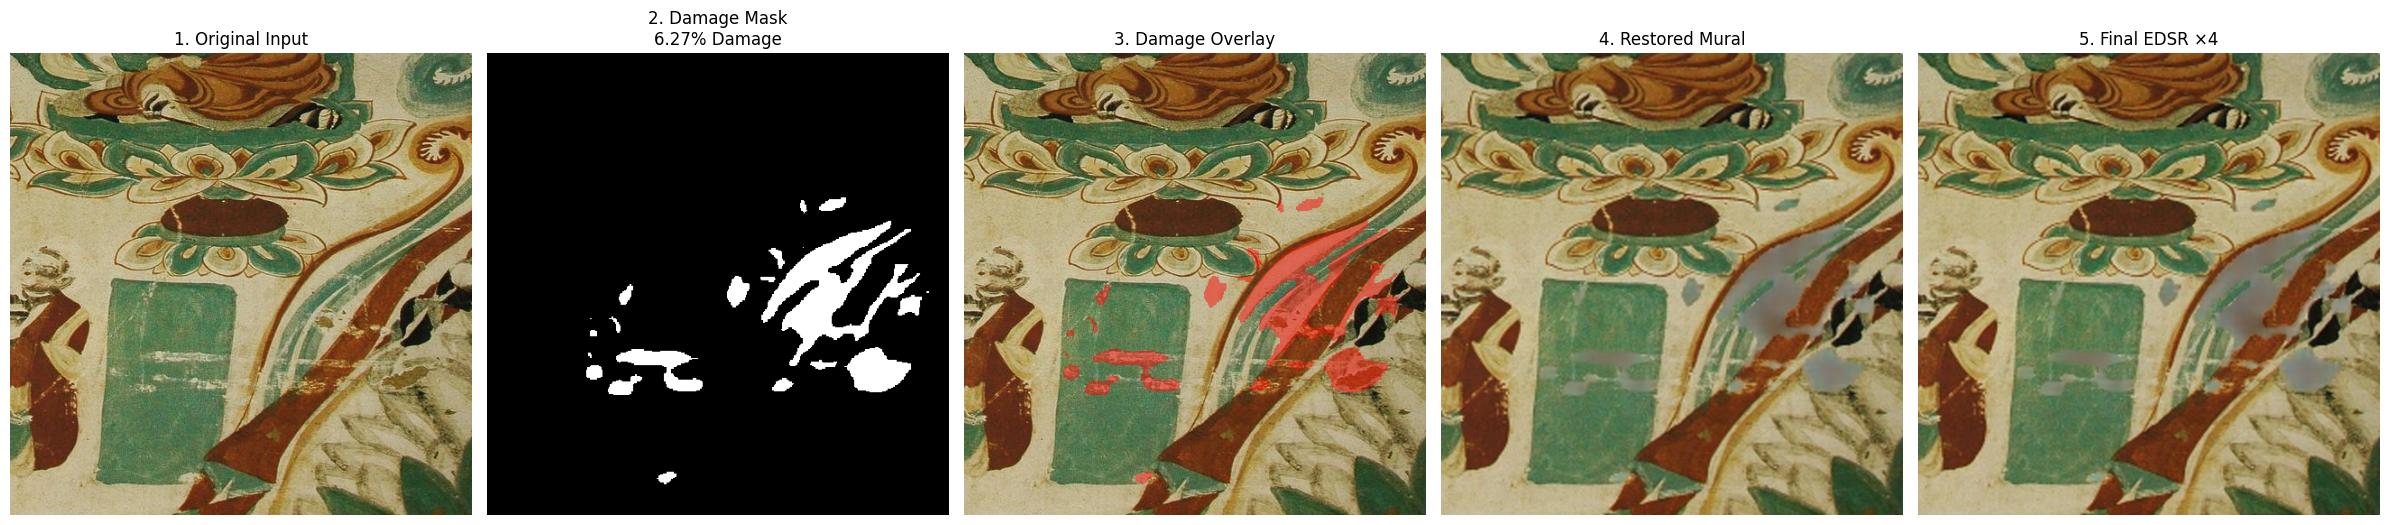


FINAL RESULT
Detected Damage : 6.27%
Original Size   : 512 x 512
Final SR Size   : 2048 x 2048
Restored Image  : /content/final_mural_results/restored_mural.png
Final SR Image  : /content/final_mural_results/final_restored_mural_x4.png


In [ ]:
# ============================================================
# ALL-IN-ONE MURAL RESTORATION INFERENCE CELL
# ============================================================

# If needed, uncomment:
# !pip install -q segmentation-models-pytorch timm

import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import segmentation_models_pytorch as smp

import tensorflow as tf
from tensorflow.keras import layers

from google.colab import files


# ============================================================
# 1. MODEL PATHS
# ============================================================

MODEL_DIR = "/content/full_mural_models/flask_models"

SEG_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "mural_damage_unetplusplus_efficientnetb3.pth"
)

SEG_METADATA_PATH = os.path.join(
    MODEL_DIR,
    "segmentation_metadata.json"
)

REST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_restoration_autoencoder.keras"
)

SR_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_mural_edsr_x4_dynamic.keras"
)


print("=" * 70)
print("CHECKING MODEL FILES")
print("=" * 70)

for path in [
    SEG_MODEL_PATH,
    SEG_METADATA_PATH,
    REST_MODEL_PATH,
    SR_MODEL_PATH
]:
    print(
        "FOUND    " if os.path.exists(path) else "NOT FOUND",
        path
    )


# ============================================================
# 2. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\nPyTorch Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 3. LOAD SEGMENTATION METADATA
# ============================================================

with open(
    SEG_METADATA_PATH,
    "r"
) as f:
    metadata = json.load(f)


ENCODER_NAME = metadata.get(
    "encoder_name",
    "efficientnet-b3"
)

SEG_IMAGE_SIZE = int(
    metadata.get(
        "image_size",
        384
    )
)

SEG_THRESHOLD = float(
    metadata.get(
        "threshold",
        0.5
    )
)

MEAN = np.array(
    metadata.get(
        "mean",
        [0.485, 0.456, 0.406]
    ),
    dtype=np.float32
)

STD = np.array(
    metadata.get(
        "std",
        [0.229, 0.224, 0.225]
    ),
    dtype=np.float32
)


print("\nSegmentation Model Settings")
print("Encoder   :", ENCODER_NAME)
print("Image Size:", SEG_IMAGE_SIZE)
print("Threshold :", SEG_THRESHOLD)


# ============================================================
# 4. LOAD SEGMENTATION MODEL
# ============================================================

seg_model = smp.UnetPlusPlus(
    encoder_name=ENCODER_NAME,
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
)

checkpoint = torch.load(
    SEG_MODEL_PATH,
    map_location=DEVICE
)

seg_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

seg_model = seg_model.to(
    DEVICE
)

seg_model.eval()

print(
    "\nSegmentation model loaded successfully."
)


# ============================================================
# 5. LOAD RESTORATION MODEL
# ============================================================

restoration_model = (
    tf.keras.models.load_model(
        REST_MODEL_PATH,
        compile=False
    )
)

print(
    "Restoration model loaded successfully."
)


# ============================================================
# 6. PIXEL SHUFFLE FOR EDSR
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="MuralRestoration"
)
class PixelShuffle(
    layers.Layer
):

    def __init__(
        self,
        scale=2,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.scale = int(
            scale
        )

    def call(
        self,
        inputs
    ):

        return tf.nn.depth_to_space(
            inputs,
            self.scale
        )

    def get_config(
        self
    ):

        config = super().get_config()

        config.update({
            "scale": self.scale
        })

        return config


# ============================================================
# 7. LOAD SUPER RESOLUTION MODEL
# ============================================================

sr_model = tf.keras.models.load_model(

    SR_MODEL_PATH,

    custom_objects={
        "PixelShuffle": PixelShuffle
    },

    compile=False,

    safe_mode=False
)

print(
    "Super-resolution model loaded successfully."
)


# ============================================================
# 8. UPLOAD INPUT IMAGE
# ============================================================

print(
    "\nUpload one mural image."
)

uploaded = files.upload()

INPUT_PATH = next(
    iter(
        uploaded.keys()
    )
)

print(
    "Selected image:",
    INPUT_PATH
)


# ============================================================
# 9. READ INPUT IMAGE
# ============================================================

input_bgr = cv2.imread(
    INPUT_PATH
)

if input_bgr is None:
    raise ValueError(
        "Could not read the uploaded image."
    )

input_rgb = cv2.cvtColor(
    input_bgr,
    cv2.COLOR_BGR2RGB
)

ORIGINAL_H, ORIGINAL_W = (
    input_rgb.shape[:2]
)

print(
    "Original image shape:",
    input_rgb.shape
)


# ============================================================
# 10. SEGMENTATION PREPROCESSING
# ============================================================

seg_input = cv2.resize(
    input_rgb,
    (
        SEG_IMAGE_SIZE,
        SEG_IMAGE_SIZE
    ),
    interpolation=cv2.INTER_AREA
)

seg_input = (
    seg_input.astype(
        np.float32
    )
    /
    255.0
)

seg_input = (
    seg_input
    -
    MEAN
) / STD

seg_input = np.transpose(
    seg_input,
    (
        2,
        0,
        1
    )
)

seg_tensor = torch.tensor(
    seg_input,
    dtype=torch.float32
).unsqueeze(
    0
).to(
    DEVICE
)


# ============================================================
# 11. DAMAGE PREDICTION
# ============================================================

with torch.no_grad():

    logits = seg_model(
        seg_tensor
    )

    probability = torch.sigmoid(
        logits
    )[
        0,
        0
    ].cpu().numpy()


print("\nPrediction Statistics")
print(
    "Min :",
    probability.min()
)

print(
    "Max :",
    probability.max()
)

print(
    "Mean:",
    probability.mean()
)


# ============================================================
# 12. CREATE DAMAGE MASK
# ============================================================

binary_mask = (
    probability
    >=
    SEG_THRESHOLD
).astype(
    np.uint8
) * 255


# Morphological cleanup
kernel = np.ones(
    (3, 3),
    np.uint8
)

binary_mask = cv2.morphologyEx(
    binary_mask,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=1
)


# Resize mask back to original image size
damage_mask = cv2.resize(
    binary_mask,
    (
        ORIGINAL_W,
        ORIGINAL_H
    ),
    interpolation=cv2.INTER_NEAREST
)


damage_percentage = (
    np.mean(
        damage_mask > 127
    )
    *
    100
)

print(
    f"\nDetected Damage Area: "
    f"{damage_percentage:.2f}%"
)


# ============================================================
# 13. DAMAGE OVERLAY
# ============================================================

overlay = input_rgb.copy()

damage_region = (
    damage_mask > 127
)

if np.any(
    damage_region
):

    overlay[
        damage_region
    ] = (
        0.55
        *
        overlay[
            damage_region
        ].astype(
            np.float32
        )
        +
        0.45
        *
        np.array(
            [255, 0, 0]
        )
    ).astype(
        np.uint8
    )


# ============================================================
# 14. RESTORATION PREPARATION
# ============================================================

REST_SIZE = 256

rest_image = cv2.resize(
    input_rgb,
    (
        REST_SIZE,
        REST_SIZE
    ),
    interpolation=cv2.INTER_AREA
)

rest_mask = cv2.resize(
    damage_mask,
    (
        REST_SIZE,
        REST_SIZE
    ),
    interpolation=cv2.INTER_NEAREST
)


rest_image_float = (
    rest_image.astype(
        np.float32
    )
    /
    255.0
)

rest_mask_binary = (
    rest_mask > 127
)

rest_mask_3ch = np.repeat(
    rest_mask_binary[
        ...,
        None
    ],
    3,
    axis=2
)


# Neutral gray corruption
damaged_input = (
    rest_image_float.copy()
)

damaged_input[
    rest_mask_3ch
] = 0.5


# ============================================================
# 15. RESTORATION PREDICTION
# ============================================================

if np.any(
    rest_mask_binary
):

    restoration_prediction = (
        restoration_model.predict(
            damaged_input[
                None,
                ...
            ],
            verbose=0
        )[0]
    )

    restoration_prediction = np.clip(
        restoration_prediction,
        0,
        1
    )

    restored_small = (
        rest_image_float.copy()
    )

    restored_small[
        rest_mask_3ch
    ] = restoration_prediction[
        rest_mask_3ch
    ]

else:

    restored_small = (
        rest_image_float.copy()
    )


restored_small_uint8 = (
    restored_small
    *
    255
).astype(
    np.uint8
)


restored_image = cv2.resize(
    restored_small_uint8,
    (
        ORIGINAL_W,
        ORIGINAL_H
    ),
    interpolation=cv2.INTER_CUBIC
)

print(
    "Restoration completed."
)


# ============================================================
# 16. PREPARE EDSR INPUT
# ============================================================

MAX_SR_INPUT = 512

h, w = restored_image.shape[
    :2
]

max_dimension = max(
    h,
    w
)

if max_dimension > MAX_SR_INPUT:

    scale_factor = (
        MAX_SR_INPUT
        /
        max_dimension
    )

    sr_w = max(
        1,
        int(
            round(
                w
                *
                scale_factor
            )
        )
    )

    sr_h = max(
        1,
        int(
            round(
                h
                *
                scale_factor
            )
        )
    )

    sr_input = cv2.resize(
        restored_image,
        (
            sr_w,
            sr_h
        ),
        interpolation=cv2.INTER_AREA
    )

else:

    sr_input = (
        restored_image.copy()
    )


# ============================================================
# 17. EDSR ×4
# ============================================================

sr_input_float = (
    sr_input.astype(
        np.float32
    )
    /
    255.0
)

sr_prediction = (
    sr_model.predict(
        sr_input_float[
            None,
            ...
        ],
        verbose=0
    )[0]
)

sr_prediction = np.clip(
    sr_prediction,
    0,
    1
)

final_sr_image = (
    sr_prediction
    *
    255
).astype(
    np.uint8
)

print(
    "Super-resolution completed."
)

print(
    "Final SR shape:",
    final_sr_image.shape
)


# ============================================================
# 18. DISPLAY ALL RESULTS
# ============================================================

plt.figure(
    figsize=(
        24,
        6
    )
)


plt.subplot(
    1,
    5,
    1
)

plt.imshow(
    input_rgb
)

plt.title(
    "1. Original Input"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    5,
    2
)

plt.imshow(
    damage_mask,
    cmap="gray"
)

plt.title(
    f"2. Damage Mask\n"
    f"{damage_percentage:.2f}% Damage"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    5,
    3
)

plt.imshow(
    overlay
)

plt.title(
    "3. Damage Overlay"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    5,
    4
)

plt.imshow(
    restored_image
)

plt.title(
    "4. Restored Mural"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    5,
    5
)

plt.imshow(
    final_sr_image
)

plt.title(
    "5. Final EDSR ×4"
)

plt.axis(
    "off"
)


plt.tight_layout()

plt.show()


# ============================================================
# 19. SAVE OUTPUTS
# ============================================================

OUTPUT_DIR = (
    "/content/final_mural_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


MASK_PATH = os.path.join(
    OUTPUT_DIR,
    "predicted_damage_mask.png"
)

OVERLAY_PATH = os.path.join(
    OUTPUT_DIR,
    "damage_overlay.png"
)

RESTORED_PATH = os.path.join(
    OUTPUT_DIR,
    "restored_mural.png"
)

FINAL_PATH = os.path.join(
    OUTPUT_DIR,
    "final_restored_mural_x4.png"
)


cv2.imwrite(
    MASK_PATH,
    damage_mask
)


cv2.imwrite(
    OVERLAY_PATH,
    cv2.cvtColor(
        overlay,
        cv2.COLOR_RGB2BGR
    )
)


cv2.imwrite(
    RESTORED_PATH,
    cv2.cvtColor(
        restored_image,
        cv2.COLOR_RGB2BGR
    )
)


cv2.imwrite(
    FINAL_PATH,
    cv2.cvtColor(
        final_sr_image,
        cv2.COLOR_RGB2BGR
    )
)


print("\n" + "=" * 70)
print("FINAL RESULT")
print("=" * 70)

print(
    "Detected Damage :",
    f"{damage_percentage:.2f}%"
)

print(
    "Original Size   :",
    f"{ORIGINAL_W} x {ORIGINAL_H}"
)

print(
    "Final SR Size   :",
    f"{final_sr_image.shape[1]} x "
    f"{final_sr_image.shape[0]}"
)

print(
    "Restored Image  :",
    RESTORED_PATH
)

print(
    "Final SR Image  :",
    FINAL_PATH
)

print("=" * 70)